
# PRDM9 accessibility feature generation — production notebook

This notebook rebuilds the **accessibility feature table** for all three window sets:

- `prdm9`
- `datasetA_matched`
- `datasetB_global`

using the accessibility bigWig track from the exploratory notebook:

- `accessibility/ENCFF668ATM.bigWig`

## Feature definition carried forward from the exploratory notebook

For each window, we compute binned summaries at fixed genomic resolution:

- `accessibility__mean`
- `accessibility__max`
- `accessibility__min`
- `accessibility__std`
- `accessibility__p90`
- `accessibility__p95`
- `accessibility__covfrac_high`
- `accessibility__local_delta_5kb`

## Production choices

The exploratory notebook had the right feature family, but several details are tightened here for publication use:

1. **All three window sets are processed together**
   - PRDM9 windows
   - `datasetA_matched`
   - `datasetB_global`

2. **Fixed-resolution binning**
   - We keep the original fast `pyBigWig.stats(..., nBins=...)` strategy at `25 bp` resolution for scalable whole-dataset processing.

3. **Main summaries are computed on zero-filled genomic bins**
   - Missing bigWig bins are treated as **0 accessibility** in the main feature table.
   - This makes windows directly comparable, instead of silently ignoring low-signal / uncovered bins.
   - A debug table also stores `accessibility__observed_bin_frac`, so track sparsity can still be audited explicitly.

4. **High-accessibility threshold**
   - `accessibility__covfrac_high` is the fraction of **all genomic bins** in a window whose signal exceeds a global threshold.
   - That threshold is estimated from a large random genomic sample of **positive bigWig bin means** on canonical chromosomes.

5. **Local context**
   - `accessibility__local_delta_5kb` is computed as:

   `window_mean - mean(flanking accessibility in [start-5kb,start) ∪ [end,end+5kb))`

   rather than mixing the window into its own neighborhood.

6. **Strict QC**
   - exact row count checks
   - unique window identity checks
   - finite numeric output checks
   - bounds checks for `covfrac_high`
   - monotonicity checks (`min <= mean <= max`, `p90 <= p95 <= max`)
   - debug outputs, validation tables, and publication-style figures

## Expected output layout

The notebook writes to:

- `data_prdm9_accessibility_production/features/`
- `data_prdm9_accessibility_production/tables/`
- `data_prdm9_accessibility_production/figures/`
- `data_prdm9_accessibility_production/metadata/`
- `data_prdm9_accessibility_production/logs/`

If `pyBigWig` is not installed in your environment, install it first in the kernel environment.


In [2]:
!pip install pyBigWig

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 7.2 MB/s eta 0:00:00


In [3]:

# ------------------------------------------------------------------
# Imports and configuration
# ------------------------------------------------------------------
import os

# Avoid BLAS/OpenMP oversubscription when using many worker processes
for env_var in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ[env_var] = "1"

import gc
import json
import math
import logging
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from tqdm.auto import tqdm
from rich.console import Console
from rich.table import Table
from rich.panel import Panel
from rich.logging import RichHandler

try:
    import pyBigWig
except ImportError as e:
    raise ImportError(
        "pyBigWig is required for this notebook. "
        "Install it in the active kernel, e.g. `pip install pyBigWig`."
    ) from e

console = Console()

RNG_SEED = 1337
RNG = np.random.default_rng(RNG_SEED)

N_CPUS = min(64, os.cpu_count() or 1)
BIN_SIZE = 25
LOCAL_RADIUS_BP = 5_000
HIGH_SIGNAL_QUANTILE = 0.80
THRESH_SAMPLE_BINS = 2_000_000
THRESH_SAMPLE_BLOCK = 20_000
CANONICAL_ONLY = True

SAMPLING_DIR = Path("data_prdm9_sampling_production")
PRDM9_BED = SAMPLING_DIR / "prdm9_filtered.bed"
DATASET_A_BED = SAMPLING_DIR / "datasetA_matched.len_gc_entropy.bed"
DATASET_B_BED = SAMPLING_DIR / "datasetB_global.length_only.bed"

ACCESSIBILITY_BIGWIG = Path("accessibility/ENCFF668ATM.bigWig")

OUTDIR = Path("data_prdm9_accessibility_production")
FIGDIR = OUTDIR / "figures"
TABDIR = OUTDIR / "tables"
FEATDIR = OUTDIR / "features"
METADIR = OUTDIR / "metadata"
LOGDIR = OUTDIR / "logs"
for p in [OUTDIR, FIGDIR, TABDIR, FEATDIR, METADIR, LOGDIR]:
    p.mkdir(parents=True, exist_ok=True)

ALL_PARQUET = FEATDIR / "accessibility_features.parquet"
DEBUG_PARQUET = FEATDIR / "accessibility_features_with_qc.parquet"
WINDOWS_TABLE = TABDIR / "all_windows.tsv"
SUMMARY_TABLE = TABDIR / "accessibility_windowset_summary.tsv"
EFFECT_TABLE = TABDIR / "accessibility_effect_summary.tsv"
THRESHOLD_TABLE = TABDIR / "threshold_sampling_summary.tsv"
WINDOWSET_SPLIT_PREFIX = FEATDIR / "accessibility_features"
RUN_METADATA_JSON = METADIR / "run_metadata.json"
LOG_PATH = LOGDIR / "accessibility_feature_generation.log"

PALETTE_WINDOWSET = {
    "prdm9": "#5B2A86",
    "datasetA_matched": "#1B9E77",
    "datasetB_global": "#D95F02",
}

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "legend.fontsize": 9,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

logger = logging.getLogger("prdm9_accessibility")
logger.setLevel(logging.INFO)
logger.handlers.clear()
logger.addHandler(RichHandler(rich_tracebacks=True, markup=True, show_time=True, show_path=False))
logger.addHandler(logging.FileHandler(LOG_PATH, mode="w"))

console.print(Panel.fit(
    "\n".join([
        "[bold]PRDM9 accessibility feature generation[/bold]",
        f"Seed: {RNG_SEED}",
        f"CPU budget: {N_CPUS}",
        f"Bin size: {BIN_SIZE} bp",
        f"Local flank radius: {LOCAL_RADIUS_BP} bp",
        f"High-signal quantile: {HIGH_SIGNAL_QUANTILE:.2f}",
        f"Threshold sample bins: {THRESH_SAMPLE_BINS:,}",
        f"Output directory: {OUTDIR.resolve()}",
    ]),
    title="Run configuration"
))
logger.info("Starting accessibility feature generation notebook")


╭───────────────────────────── Run configuration ──────────────────────────────╮
│ PRDM9 accessibility feature generation                                       │
│ Seed: 1337                                                                   │
│ CPU budget: 64                                                               │
│ Bin size: 25 bp                                                              │
│ Local flank radius: 5000 bp                                                  │
│ High-signal quantile: 0.80                                                   │
│ Threshold sample bins: 2,000,000                                             │
│ Output directory: /home/jovyan/prdm9_new/data_prdm9_accessibility_production │
╰──────────────────────────────────────────────────────────────────────────────╯

[04/16/26 18:25:35] INFO     Starting accessibility feature generation notebook

In [4]:

# ------------------------------------------------------------------
# Utility helpers
# ------------------------------------------------------------------
def canonical_chromosomes():
    return [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]


def read_bed3(path: Path, windowset_name: str) -> pd.DataFrame:
    df = pd.read_csv(path, sep="\t", header=None, usecols=[0, 1, 2], names=["Chromosome", "Start", "End"])
    df["Chromosome"] = df["Chromosome"].astype(str)
    df["Start"] = df["Start"].astype(np.int64)
    df["End"] = df["End"].astype(np.int64)
    if ((df["End"] - df["Start"]) <= 0).any():
        bad = df.loc[(df["End"] - df["Start"]) <= 0].head()
        raise ValueError(f"{path} contains non-positive intervals:\n{bad}")
    if CANONICAL_ONLY:
        df = df[df["Chromosome"].isin(canonical_chromosomes())].copy()
    df["WindowSet"] = windowset_name
    return df


def add_window_id(df: pd.DataFrame, start_id: int) -> pd.DataFrame:
    df = df.copy()
    df["window_id"] = np.arange(start_id, start_id + len(df), dtype=np.int64)
    df["window_length_bp"] = (df["End"] - df["Start"]).astype(np.int64)
    return df


def safe_ratio(num: float, den: float) -> float:
    if pd.isna(num) or pd.isna(den) or den == 0:
        return np.nan
    return float(num / den)


def cohens_d(x: np.ndarray, y: np.ndarray) -> float:
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x = x[np.isfinite(x)]
    y = y[np.isfinite(y)]
    if len(x) < 2 or len(y) < 2:
        return np.nan
    vx = x.var(ddof=1)
    vy = y.var(ddof=1)
    pooled = ((len(x) - 1) * vx + (len(y) - 1) * vy) / (len(x) + len(y) - 2)
    if pooled <= 0:
        return np.nan
    return float((x.mean() - y.mean()) / math.sqrt(pooled))


def quantile_clip_series(s: pd.Series, q_low=0.005, q_high=0.995) -> pd.Series:
    lo, hi = s.quantile([q_low, q_high])
    return s.clip(lower=float(lo), upper=float(hi))


logger.info("Loading windows from production sampling outputs")
prdm9_df = read_bed3(PRDM9_BED, "prdm9")
datasetA_df = read_bed3(DATASET_A_BED, "datasetA_matched")
datasetB_df = read_bed3(DATASET_B_BED, "datasetB_global")

prdm9_df = add_window_id(prdm9_df, 0)
datasetA_df = add_window_id(datasetA_df, len(prdm9_df))
datasetB_df = add_window_id(datasetB_df, len(prdm9_df) + len(datasetA_df))

windows = pd.concat([prdm9_df, datasetA_df, datasetB_df], ignore_index=True)
windows = windows[["WindowSet", "Chromosome", "Start", "End", "window_length_bp", "window_id"]].copy()

if windows["window_id"].duplicated().any():
    raise ValueError("window_id is not unique")
if windows[["WindowSet", "Chromosome", "Start", "End"]].duplicated().any():
    dup = windows.loc[windows[["WindowSet", "Chromosome", "Start", "End"]].duplicated(keep=False)].head()
    raise ValueError(f"Duplicate windows detected:\n{dup}")

windows.to_csv(WINDOWS_TABLE, sep="\t", index=False)

tbl = Table(title="Window counts")
tbl.add_column("WindowSet")
tbl.add_column("N windows", justify="right")
tbl.add_column("Median length", justify="right")
for ws, sub in windows.groupby("WindowSet", sort=False):
    tbl.add_row(ws, f"{len(sub):,}", f"{int(sub['window_length_bp'].median()):,}")
console.print(tbl)

logger.info("Loaded %s windows total", f"{len(windows):,}")
logger.info("Window counts by set: %s", windows["WindowSet"].value_counts().to_dict())


                    INFO     Loading windows from production sampling outputs

                 Window counts                  
┏━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ WindowSet        ┃ N windows ┃ Median length ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ prdm9            │    60,580 │           717 │
│ datasetA_matched │   181,740 │           717 │
│ datasetB_global  │   181,740 │           717 │
└──────────────────┴───────────┴───────────────┘

[04/16/26 18:25:36] INFO     Loaded 424,060 windows total

                    INFO     Window counts by set: {'datasetA_matched': 181740, 'datasetB_global': 181740, 'prdm9':
                             60580}

                    INFO     Opening bigWig: accessibility/ENCFF668ATM.bigWig

                    INFO     Sampling threshold from 23 canonical chromosomes

threshold bins:   0%|          | 0/2000000 [00:00<?, ?it/s]

[04/16/26 18:30:10] INFO     High-signal threshold source: positive_sampled_bins

                    INFO     Estimated high-signal threshold: 0.252548

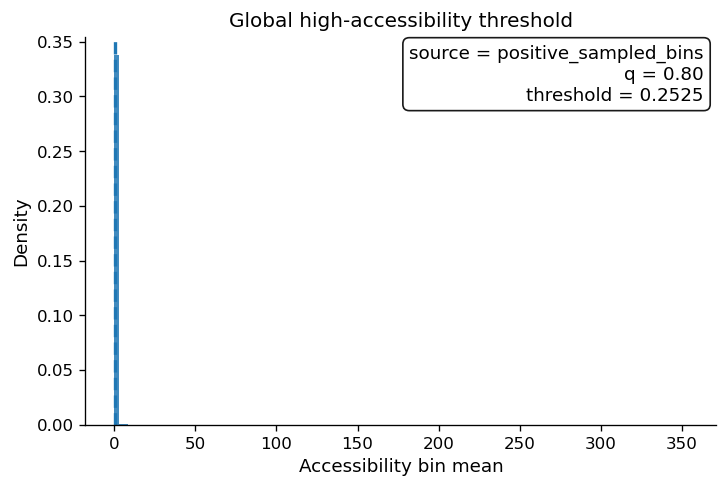

In [5]:

# ------------------------------------------------------------------
# Inspect bigWig and estimate the global "high accessibility" threshold
# ------------------------------------------------------------------
logger.info("Opening bigWig: %s", ACCESSIBILITY_BIGWIG)
bw = pyBigWig.open(str(ACCESSIBILITY_BIGWIG))
chrom_sizes = bw.chroms()

canonical = set(canonical_chromosomes())
window_chroms = [c for c in windows["Chromosome"].drop_duplicates() if c in chrom_sizes]
if CANONICAL_ONLY:
    sample_chroms = [c for c in window_chroms if c in canonical]
else:
    sample_chroms = list(window_chroms)

if not sample_chroms:
    raise ValueError("No sampled chromosomes are available in the bigWig")

sample_lengths = np.array([chrom_sizes[c] for c in sample_chroms], dtype=np.int64)
sample_probs = sample_lengths / sample_lengths.sum()

logger.info("Sampling threshold from %d canonical chromosomes", len(sample_chroms))
positive_samples = []
all_samples = []
rng = np.random.default_rng(RNG_SEED)
target = THRESH_SAMPLE_BINS

with tqdm(total=target, desc="threshold bins") as pbar:
    while len(all_samples) < target:
        idx = rng.choice(len(sample_chroms), size=THRESH_SAMPLE_BLOCK, replace=True, p=sample_probs)
        for ci in idx:
            chrom = sample_chroms[int(ci)]
            L = int(chrom_sizes[chrom])
            if L <= BIN_SIZE:
                continue
            start = int(rng.integers(0, L - BIN_SIZE))
            end = start + BIN_SIZE
            try:
                v = bw.stats(chrom, start, end, type="mean", nBins=1)[0]
            except RuntimeError:
                v = None
            if v is None or (isinstance(v, float) and np.isnan(v)):
                value = 0.0
            else:
                value = float(v)
            all_samples.append(value)
            if value > 0:
                positive_samples.append(value)
            if len(all_samples) >= target:
                break
        pbar.update(min(THRESH_SAMPLE_BLOCK, target - pbar.n))

bw.close()

all_samples = np.asarray(all_samples[:target], dtype=np.float32)
positive_samples = np.asarray(positive_samples, dtype=np.float32)

if positive_samples.size < 10_000:
    logger.warning(
        "Only %d positive sampled bins found; falling back to all finite samples for threshold estimation",
        positive_samples.size,
    )
    threshold_source = "all_sampled_bins"
    threshold_values = all_samples
else:
    threshold_source = "positive_sampled_bins"
    threshold_values = positive_samples

high_signal_threshold = float(np.quantile(threshold_values, HIGH_SIGNAL_QUANTILE))

threshold_summary = pd.DataFrame([{
    "threshold_source": threshold_source,
    "n_all_sampled_bins": int(all_samples.size),
    "n_positive_sampled_bins": int(positive_samples.size),
    "positive_sample_fraction": float((all_samples > 0).mean()),
    "all_sample_mean": float(all_samples.mean()),
    "all_sample_median": float(np.median(all_samples)),
    "all_sample_p95": float(np.quantile(all_samples, 0.95)),
    "positive_sample_mean": float(positive_samples.mean()) if positive_samples.size else np.nan,
    "positive_sample_median": float(np.median(positive_samples)) if positive_samples.size else np.nan,
    "positive_sample_p95": float(np.quantile(positive_samples, 0.95)) if positive_samples.size else np.nan,
    "high_signal_quantile": float(HIGH_SIGNAL_QUANTILE),
    "high_signal_threshold": float(high_signal_threshold),
    "bin_size_bp": int(BIN_SIZE),
}])
threshold_summary.to_csv(THRESHOLD_TABLE, sep="\t", index=False)

logger.info("High-signal threshold source: %s", threshold_source)
logger.info("Estimated high-signal threshold: %.6g", high_signal_threshold)

fig, ax = plt.subplots(figsize=(6.2, 4.2))
plot_vals = pd.Series(threshold_values).sample(min(200_000, len(threshold_values)), random_state=RNG_SEED)
ax.hist(plot_vals, bins=120, density=True, alpha=0.85)
ax.axvline(high_signal_threshold, linestyle="--", linewidth=2)
ax.set_xlabel("Accessibility bin mean")
ax.set_ylabel("Density")
ax.set_title("Global high-accessibility threshold")
ax.text(
    0.98, 0.98,
    f"source = {threshold_source}\nq = {HIGH_SIGNAL_QUANTILE:.2f}\nthreshold = {high_signal_threshold:.4g}",
    transform=ax.transAxes,
    ha="right", va="top",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="black", alpha=0.9),
)
fig.tight_layout()
fig.savefig(FIGDIR / "accessibility_threshold_distribution.png", bbox_inches="tight")
plt.show()


In [6]:

# ------------------------------------------------------------------
# Parallel feature extraction
# ------------------------------------------------------------------
_G_BW = None
_G_CHROMS = None
_G_BIN = None
_G_LOCAL = None
_G_THR = None

def _init_worker(bigwig_path: str, bin_size: int, local_radius_bp: int, high_signal_threshold: float):
    global _G_BW, _G_CHROMS, _G_BIN, _G_LOCAL, _G_THR
    _G_BW = pyBigWig.open(bigwig_path)
    _G_CHROMS = _G_BW.chroms()
    _G_BIN = int(bin_size)
    _G_LOCAL = int(local_radius_bp)
    _G_THR = float(high_signal_threshold)


def _clip_interval(chrom: str, start: int, end: int):
    if chrom not in _G_CHROMS:
        return False, 0, 0
    chrom_len = int(_G_CHROMS[chrom])
    s = max(0, int(start))
    e = min(chrom_len, int(end))
    if s >= e:
        return False, 0, 0
    return True, s, e


def _get_binned_signal(chrom: str, start: int, end: int):
    ok, s, e = _clip_interval(chrom, start, end)
    if not ok:
        return None, 0.0, 0
    L = e - s
    n_bins = int((L + _G_BIN - 1) // _G_BIN)
    if n_bins <= 0:
        return None, 0.0, 0
    try:
        vals = _G_BW.stats(chrom, s, e, type="mean", nBins=n_bins)
    except RuntimeError:
        return None, 0.0, 0
    arr = np.array([np.nan if v is None else float(v) for v in vals], dtype=np.float32)
    observed_bin_frac = float(np.isfinite(arr).mean()) if arr.size else 0.0
    arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)
    return arr, observed_bin_frac, int(arr.size)


def _flank_mean(chrom: str, start: int, end: int):
    left_arr, _, left_n = _get_binned_signal(chrom, start - _G_LOCAL, start)
    right_arr, _, right_n = _get_binned_signal(chrom, end, end + _G_LOCAL)

    pieces = []
    if left_arr is not None and left_n > 0:
        pieces.append(left_arr)
    if right_arr is not None and right_n > 0:
        pieces.append(right_arr)

    if not pieces:
        return 0.0, 0
    combined = np.concatenate(pieces)
    return float(combined.mean()), int(combined.size)


def _process_chunk(df_chunk: pd.DataFrame):
    rows = []
    for r in df_chunk.itertuples(index=False):
        chrom = r.Chromosome
        start = int(r.Start)
        end = int(r.End)
        wid = int(r.window_id)

        arr, observed_frac, n_bins = _get_binned_signal(chrom, start, end)
        if arr is None or n_bins == 0:
            rows.append((
                wid,
                0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
                observed_frac, int(n_bins), 0.0, 0,
            ))
            continue

        mean = float(arr.mean())
        max_ = float(arr.max())
        min_ = float(arr.min())
        std = float(arr.std())
        p90 = float(np.quantile(arr, 0.90))
        p95 = float(np.quantile(arr, 0.95))
        covfrac_high = float((arr > _G_THR).mean())

        flank_mean, flank_n_bins = _flank_mean(chrom, start, end)
        local_delta = float(mean - flank_mean)

        rows.append((
            wid,
            mean, max_, min_, std, p90, p95, covfrac_high, local_delta,
            observed_frac, int(n_bins), float(flank_mean), int(flank_n_bins),
        ))
    return rows


logger.info("Launching parallel accessibility extraction")

CHUNK_SIZE = 2000
chunks = [
    windows.iloc[i:i + CHUNK_SIZE][["Chromosome", "Start", "End", "window_id"]].copy()
    for i in range(0, len(windows), CHUNK_SIZE)
]

logger.info("Prepared %d chunks for %d windows", len(chunks), len(windows))

results = []
with ProcessPoolExecutor(
    max_workers=N_CPUS,
    initializer=_init_worker,
    initargs=(str(ACCESSIBILITY_BIGWIG), BIN_SIZE, LOCAL_RADIUS_BP, high_signal_threshold),
) as ex:
    futures = [ex.submit(_process_chunk, chunk) for chunk in chunks]
    for fut in tqdm(as_completed(futures), total=len(futures), desc="chunks"):
        results.extend(fut.result())

feature_cols = [
    "window_id",
    "accessibility__mean",
    "accessibility__max",
    "accessibility__min",
    "accessibility__std",
    "accessibility__p90",
    "accessibility__p95",
    "accessibility__covfrac_high",
    "accessibility__local_delta_5kb",
    "accessibility__observed_bin_frac",
    "accessibility__n_bins",
    "accessibility__flank_mean_5kb",
    "accessibility__flank_n_bins_5kb",
]

feat = pd.DataFrame(results, columns=feature_cols)
feat["window_id"] = feat["window_id"].astype(np.int64)
for c in feature_cols[1:]:
    if c.endswith("__n_bins") or c.endswith("_n_bins_5kb"):
        feat[c] = feat[c].astype(np.int32)
    else:
        feat[c] = feat[c].astype(np.float32)

features = windows.merge(feat, on="window_id", how="left", validate="one_to_one")

del results, feat, chunks
gc.collect()

logger.info("Accessibility features assembled: %s", features.shape)
features.head()


                    INFO     Launching parallel accessibility extraction

                    INFO     Prepared 213 chunks for 424060 windows

chunks:   0%|          | 0/213 [00:00<?, ?it/s]

[04/16/26 18:37:40] INFO     Accessibility features assembled: (424060, 18)

,WindowSet,Chromosome,Start,End,window_length_bp,window_id,accessibility__mean,accessibility__max,accessibility__min,accessibility__std,accessibility__p90,accessibility__p95,accessibility__covfrac_high,accessibility__local_delta_5kb,accessibility__observed_bin_frac,accessibility__n_bins,accessibility__flank_mean_5kb,accessibility__flank_n_bins_5kb
0,prdm9,chr1,15638,17806,2168,0,0.119449,0.244055,0.060389,0.027937,0.137643,0.166510,0.0,0.026077,1.0,87,0.093373,400
1,prdm9,chr1,29251,29752,501,1,0.076898,0.082214,0.070347,0.003621,0.081687,0.081955,0.0,0.004568,1.0,21,0.072330,400
2,prdm9,chr1,34779,35008,229,2,0.064489,0.066901,0.062335,0.001336,0.066491,0.066696,0.0,-0.002174,1.0,10,0.066663,400
3,prdm9,chr1,35827,36151,324,3,0.067932,0.071132,0.060904,0.002991,0.070814,0.070941,0.0,-0.001714,1.0,13,0.069646,400
4,prdm9,chr1,133287,133519,232,4,0.056147,0.061374,0.051205,0.003196,0.060666,0.061020,0.0,-0.023833,1.0,10,0.079980,400


In [8]:

# ------------------------------------------------------------------
# Validation and export
# ------------------------------------------------------------------
main_feature_cols = [
    "accessibility__mean",
    "accessibility__max",
    "accessibility__min",
    "accessibility__std",
    "accessibility__p90",
    "accessibility__p95",
    "accessibility__covfrac_high",
    "accessibility__local_delta_5kb",
]

debug_feature_cols = main_feature_cols + [
    "accessibility__observed_bin_frac",
    "accessibility__n_bins",
    "accessibility__flank_mean_5kb",
    "accessibility__flank_n_bins_5kb",
]

if len(features) != len(windows):
    raise ValueError("Merged features row count does not match windows row count")
if features["window_id"].duplicated().any():
    raise ValueError("window_id is duplicated after merge")
if features[["WindowSet", "Chromosome", "Start", "End"]].duplicated().any():
    raise ValueError("Window identity duplicated after merge")

if features[debug_feature_cols].isna().any().any():
    bad = features.loc[features[debug_feature_cols].isna().any(axis=1)].head()
    raise ValueError(f"NaN values detected in feature output:\n{bad}")

finite_mask = np.isfinite(features[debug_feature_cols].to_numpy(dtype=float))
if not finite_mask.all():
    raise ValueError("Non-finite values detected in feature output")

if ((features["accessibility__covfrac_high"] < 0) | (features["accessibility__covfrac_high"] > 1)).any():
    raise ValueError("accessibility__covfrac_high is outside [0, 1]")
if ((features["accessibility__observed_bin_frac"] < 0) | (features["accessibility__observed_bin_frac"] > 1)).any():
    raise ValueError("accessibility__observed_bin_frac is outside [0, 1]")

if (features["accessibility__min"] > features["accessibility__mean"]).any():
    raise ValueError("Found windows with min > mean")
if (features["accessibility__mean"] > features["accessibility__max"]).any():
    raise ValueError("Found windows with mean > max")
if (features["accessibility__p90"] > features["accessibility__p95"]).any():
    raise ValueError("Found windows with p90 > p95")
if (features["accessibility__p95"] > features["accessibility__max"]).any():
    raise ValueError("Found windows with p95 > max")
if (features["accessibility__n_bins"] < 0).any():
    bad = features.loc[features["accessibility__n_bins"] < 0].head()
    raise ValueError(f"Found windows with non-positive n_bins:\n{bad}")

all_out = features[["WindowSet", "Chromosome", "Start", "End", "window_length_bp", "window_id"] + main_feature_cols].copy()
debug_out = features[["WindowSet", "Chromosome", "Start", "End", "window_length_bp", "window_id"] + debug_feature_cols].copy()

all_out.to_parquet(ALL_PARQUET, index=False)
debug_out.to_parquet(DEBUG_PARQUET, index=False)

for ws, sub in all_out.groupby("WindowSet", sort=False):
    path = Path(f"{WINDOWSET_SPLIT_PREFIX}.{ws}.parquet")
    sub.to_parquet(path, index=False)
    logger.info("Wrote split parquet: %s", path)

summary_rows = []
for ws, sub in features.groupby("WindowSet", sort=False):
    row = {"WindowSet": ws, "n_windows": int(len(sub))}
    for col in main_feature_cols + ["accessibility__observed_bin_frac"]:
        row[f"{col}__mean"] = float(sub[col].mean())
        row[f"{col}__median"] = float(sub[col].median())
    summary_rows.append(row)
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(SUMMARY_TABLE, sep="\t", index=False)

comparison_rows = []
ref = features.loc[features["WindowSet"] == "prdm9"].copy()
for bg in ["datasetA_matched", "datasetB_global"]:
    bg_df = features.loc[features["WindowSet"] == bg].copy()
    for col in main_feature_cols:
        comparison_rows.append({
            "comparison": f"prdm9_vs_{bg}",
            "feature": col,
            "prdm9_mean": float(ref[col].mean()),
            "background_mean": float(bg_df[col].mean()),
            "prdm9_median": float(ref[col].median()),
            "background_median": float(bg_df[col].median()),
            "mean_ratio": safe_ratio(ref[col].mean(), bg_df[col].mean()),
            "median_ratio": safe_ratio(ref[col].median(), bg_df[col].median()),
            "cohens_d": cohens_d(ref[col].to_numpy(), bg_df[col].to_numpy()),
        })
effect_df = pd.DataFrame(comparison_rows)
effect_df.to_csv(EFFECT_TABLE, sep="\t", index=False)

metadata = {
    "rng_seed": RNG_SEED,
    "n_cpus": N_CPUS,
    "bin_size_bp": BIN_SIZE,
    "local_radius_bp": LOCAL_RADIUS_BP,
    "high_signal_quantile": HIGH_SIGNAL_QUANTILE,
    "high_signal_threshold": float(high_signal_threshold),
    "threshold_source": threshold_source,
    "threshold_sample_bins": int(THRESH_SAMPLE_BINS),
    "canonical_only": bool(CANONICAL_ONLY),
    "n_windows_total": int(len(windows)),
    "window_counts": {k: int(v) for k, v in windows["WindowSet"].value_counts().to_dict().items()},
    "main_feature_columns": main_feature_cols,
    "debug_feature_columns": [c for c in debug_feature_cols if c not in main_feature_cols],
    "bigwig_path": str(ACCESSIBILITY_BIGWIG),
}
with open(RUN_METADATA_JSON, "w") as f:
    json.dump(metadata, f, indent=2)

tbl = Table(title="Accessibility export summary")
tbl.add_column("Artifact")
tbl.add_column("Path")
tbl.add_row("main parquet", str(ALL_PARQUET))
tbl.add_row("debug parquet", str(DEBUG_PARQUET))
tbl.add_row("summary table", str(SUMMARY_TABLE))
tbl.add_row("effect table", str(EFFECT_TABLE))
tbl.add_row("metadata", str(RUN_METADATA_JSON))
console.print(tbl)

logger.info("Validation and export complete")
summary_df


[04/17/26 09:09:28] INFO     Wrote split parquet:                                                                  
                             data_prdm9_accessibility_production/features/accessibility_features.prdm9.parquet

                    INFO     Wrote split parquet:                                                                  
                             data_prdm9_accessibility_production/features/accessibility_features.datasetA_matched.p
                             arquet

                    INFO     Wrote split parquet:                                                                  
                             data_prdm9_accessibility_production/features/accessibility_features.datasetB_global.pa
                             rquet

                                     Accessibility export summary                                      
┏━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Artifact      ┃ Path                                                                                ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ main parquet  │ data_prdm9_accessibility_production/features/accessibility_features.parquet         │
│ debug parquet │ data_prdm9_accessibility_production/features/accessibility_features_with_qc.parquet │
│ summary table │ data_prdm9_accessibility_production/tables/accessibility_windowset_summary.tsv      │
│ effect table  │ data_prdm9_accessibility_production/tables/accessibility_effect_summary.tsv         │
│ metadata      │ data_prdm9_accessibility_production/metadata/run_metadata.json                      │
└───────────────┴─────────────────────────────────────────────────────────────────────────────────────┘

                    INFO     Validation and export complete

,WindowSet,n_windows,accessibility__mean__mean,accessibility__mean__median,accessibility__max__mean,accessibility__max__median,accessibility__min__mean,accessibility__min__median,accessibility__std__mean,accessibility__std__median,accessibility__p90__mean,accessibility__p90__median,accessibility__p95__mean,accessibility__p95__median,accessibility__covfrac_high__mean,accessibility__covfrac_high__median,accessibility__local_delta_5kb__mean,accessibility__local_delta_5kb__median,accessibility__observed_bin_frac__mean,accessibility__observed_bin_frac__median
0,prdm9,60580,1.978743,0.335841,8.090872,0.626034,0.287754,0.140362,1.972538,0.117321,4.621121,0.484174,5.912133,0.536430,0.632674,0.715943,1.416874,0.057588,0.998514,1.0
1,datasetA_matched,181740,2.058583,0.286644,8.925202,0.510093,0.248374,0.112981,2.248161,0.090815,5.078583,0.400510,6.532017,0.441842,0.518182,0.571429,1.525497,0.013406,0.991510,1.0
2,datasetB_global,181740,0.263502,0.171669,0.870935,0.304331,0.072688,0.061610,0.190978,0.059628,0.497213,0.248940,0.619366,0.269534,0.198165,0.102273,-0.040667,-0.010366,0.999978,1.0



## Validation figures

The main publication-facing checks here are:

- whether PRDM9 windows show systematically shifted accessibility summaries relative to both null datasets
- whether the signal shift is robust across *magnitude* (`mean`, `p95`) and *spatial extent* (`covfrac_high`)
- whether local accessibility enrichment persists after comparing each window to its flanks (`local_delta_5kb`)
- whether any observed pattern could be explained by track sparsity (`observed_bin_frac`)


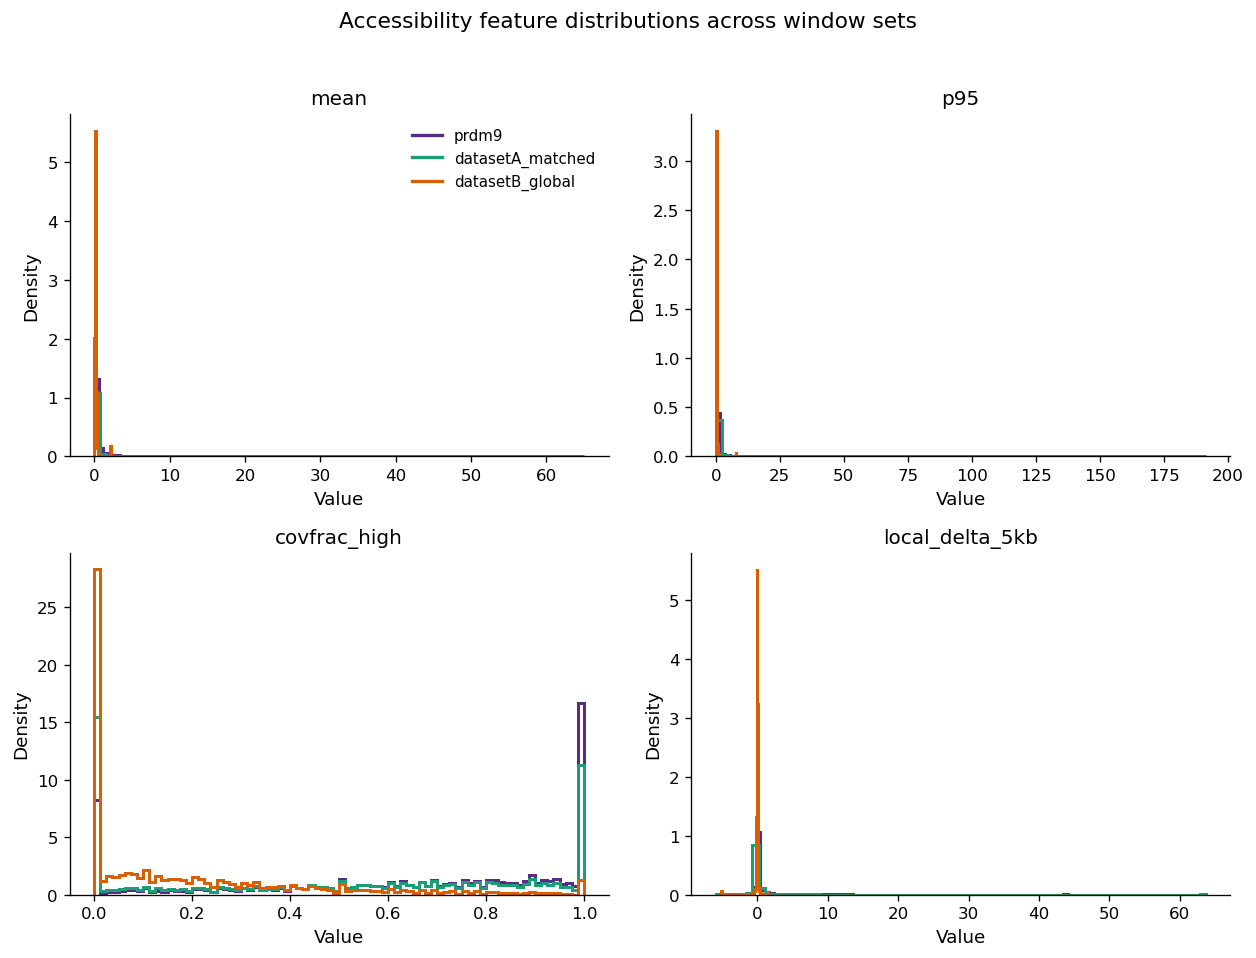

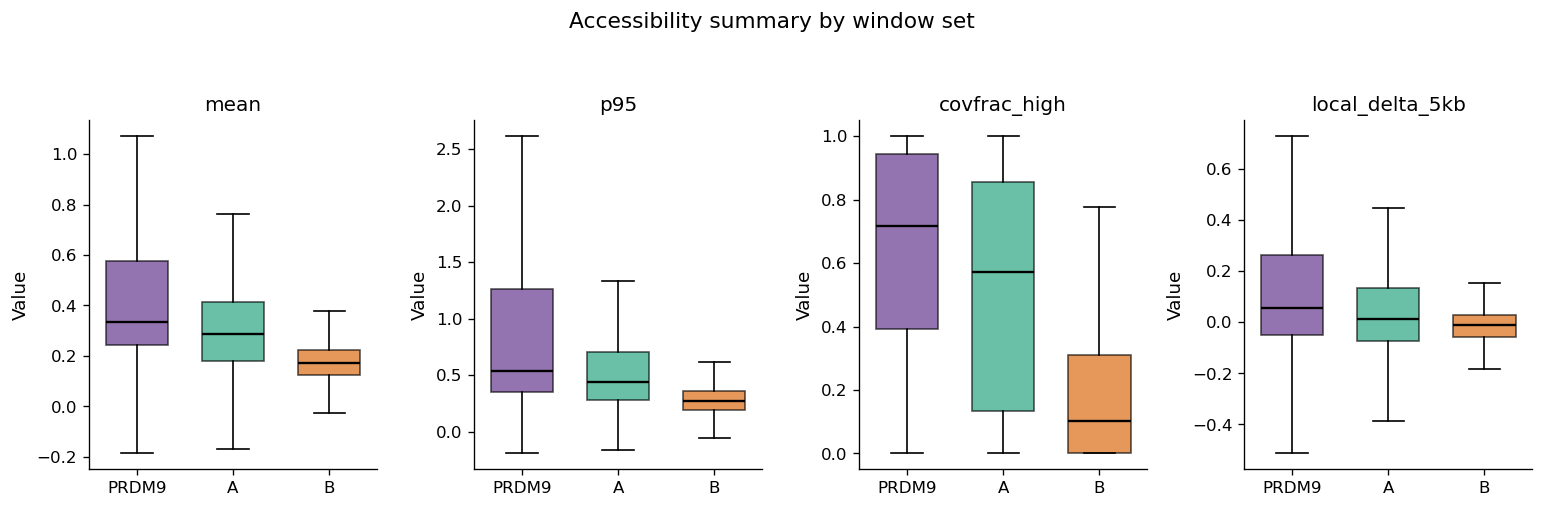

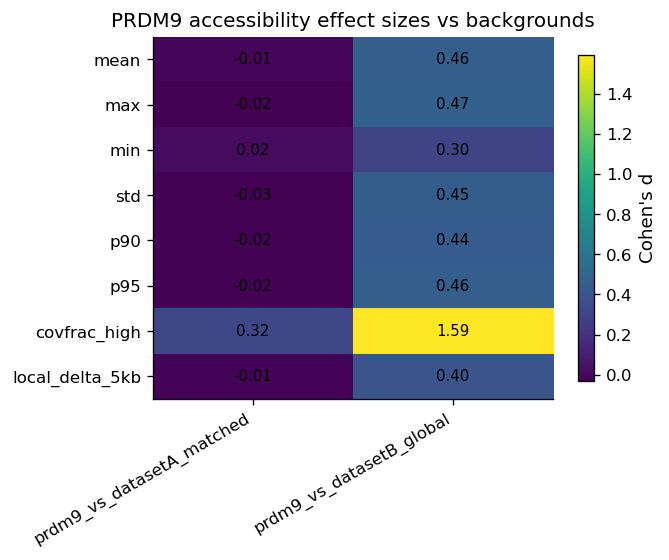

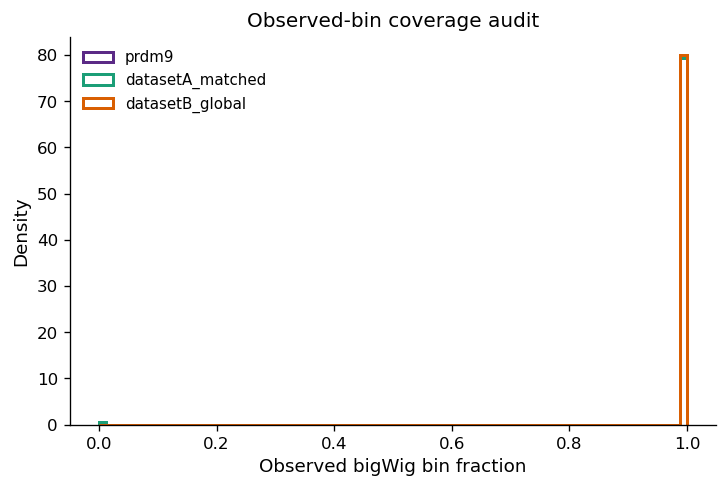

In [9]:

# ------------------------------------------------------------------
# Publication-style validation figures
# ------------------------------------------------------------------
plot_df = features.copy()

# 1) Distribution panels for key features
feature_panels = [
    "accessibility__mean",
    "accessibility__p95",
    "accessibility__covfrac_high",
    "accessibility__local_delta_5kb",
]

fig, axes = plt.subplots(2, 2, figsize=(10.6, 7.8))
axes = axes.ravel()

for ax, col in zip(axes, feature_panels):
    for ws in ["prdm9", "datasetA_matched", "datasetB_global"]:
        sub = plot_df.loc[plot_df["WindowSet"] == ws, col].astype(float)
        sub = quantile_clip_series(sub, 0.005, 0.995)
        ax.hist(
            sub,
            bins=80,
            density=True,
            histtype="step",
            linewidth=1.8,
            color=PALETTE_WINDOWSET[ws],
            label=ws,
        )
    ax.set_title(col.replace("accessibility__", ""))
    ax.set_ylabel("Density")
    ax.set_xlabel("Value")

handles = [Line2D([0], [0], color=PALETTE_WINDOWSET[ws], lw=2, label=ws) for ws in ["prdm9", "datasetA_matched", "datasetB_global"]]
axes[0].legend(handles=handles, frameon=False, loc="best")
fig.suptitle("Accessibility feature distributions across window sets", y=1.02, fontsize=13)
fig.tight_layout()
fig.savefig(FIGDIR / "accessibility_distribution_panels.png", bbox_inches="tight")
plt.show()

# 2) Boxplot-style summary for key features
fig, axes = plt.subplots(1, 4, figsize=(13.0, 4.0))
for ax, col in zip(axes, feature_panels):
    data = [plot_df.loc[plot_df["WindowSet"] == ws, col].astype(float).to_numpy() for ws in ["prdm9", "datasetA_matched", "datasetB_global"]]
    bp = ax.boxplot(
        data,
        labels=["PRDM9", "A", "B"],
        patch_artist=True,
        showfliers=False,
        widths=0.65,
    )
    for patch, ws in zip(bp["boxes"], ["prdm9", "datasetA_matched", "datasetB_global"]):
        patch.set_facecolor(PALETTE_WINDOWSET[ws])
        patch.set_alpha(0.65)
    for median in bp["medians"]:
        median.set_color("black")
        median.set_linewidth(1.4)
    ax.set_title(col.replace("accessibility__", ""))
    ax.set_ylabel("Value")
fig.suptitle("Accessibility summary by window set", y=1.05, fontsize=13)
fig.tight_layout()
fig.savefig(FIGDIR / "accessibility_boxplots.png", bbox_inches="tight")
plt.show()

# 3) Effect-size heatmap: PRDM9 vs each background
effect_plot = effect_df.pivot(index="feature", columns="comparison", values="cohens_d").reindex(main_feature_cols)
fig, ax = plt.subplots(figsize=(5.7, 4.8))
im = ax.imshow(effect_plot.to_numpy(dtype=float), aspect="auto")
ax.set_xticks(np.arange(effect_plot.shape[1]))
ax.set_xticklabels(effect_plot.columns, rotation=30, ha="right")
ax.set_yticks(np.arange(effect_plot.shape[0]))
ax.set_yticklabels([s.replace("accessibility__", "") for s in effect_plot.index])
for i in range(effect_plot.shape[0]):
    for j in range(effect_plot.shape[1]):
        val = effect_plot.iloc[i, j]
        if pd.notna(val):
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=9)
cbar = fig.colorbar(im, ax=ax, shrink=0.9)
cbar.set_label("Cohen's d")
ax.set_title("PRDM9 accessibility effect sizes vs backgrounds")
fig.tight_layout()
fig.savefig(FIGDIR / "accessibility_effect_heatmap.png", bbox_inches="tight")
plt.show()

# 4) Track sparsity / coverage audit
fig, ax = plt.subplots(figsize=(6.2, 4.2))
for ws in ["prdm9", "datasetA_matched", "datasetB_global"]:
    sub = plot_df.loc[plot_df["WindowSet"] == ws, "accessibility__observed_bin_frac"].astype(float)
    ax.hist(
        sub,
        bins=80,
        density=True,
        histtype="step",
        linewidth=1.8,
        color=PALETTE_WINDOWSET[ws],
        label=ws,
    )
ax.set_xlabel("Observed bigWig bin fraction")
ax.set_ylabel("Density")
ax.set_title("Observed-bin coverage audit")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGDIR / "accessibility_observed_bin_fraction.png", bbox_inches="tight")
plt.show()



## Notes for downstream merging

The main merge-ready table is:

- `data_prdm9_accessibility_production/features/accessibility_features.parquet`

It contains exactly one row per window and includes:

- `WindowSet`
- `Chromosome`
- `Start`
- `End`
- `window_length_bp`
- `window_id`

plus the main accessibility features.

The debug parquet keeps extra QC columns (`observed_bin_frac`, bin counts, flank means) that are helpful for checking signal sparsity or diagnosing unexpected downstream effects.
